# MCA Mini-Project: Toxic Comment Detection
## Activity 2: Feature Extraction, Model Building & Evaluation (Phase 2)

**Project Title:** Toxic Comment Detection Using Natural Language Processing and Machine Learning  
**Domain:** Natural Language Processing (NLP) & Supervised Machine Learning  
**Target Course:** Master of Computer Applications (MCA) Mini-Project  

---

### 1. Project Overview & Objectives
Online harassment, abusive language, and toxic commentary undermine positive digital discourse across online forums, social networks, and collaborative platforms. The objective of this project is to develop an automated Natural Language Processing (NLP) system capable of identifying toxic comments.

In **Activity 1**, we explored the dataset, curated a balanced 200-sample human-annotated corpus (`toxic_comments_200_annotated.csv`), and examined text preprocessing steps.

In **Activity 2**, we build the complete end-to-end Machine Learning pipeline:
1. **Linguistic Preprocessing:** Standardize cleaning, tokenization, stop-word removal, and WordNet lemmatization.
2. **Data Partitioning (No Data Leakage):** Stratify into 80% train and 20% test sets *before* vectorization.
3. **TF-IDF Feature Representation:** Extract n-gram features fitted strictly on training data.
4. **Model Development:** Train two complementary baseline classifiers:
   - **Logistic Regression** (Linear discriminative model with balanced class weighting)
   - **Multinomial Naive Bayes** (Probabilistic generative model with Laplace smoothing)
5. **Comprehensive Evaluation:** Accuracy, Precision, Recall, F1-Score, Classification Reports, and Confusion Matrices.
6. **Visual Analysis:** Class distributions, side-by-side metric charts, and confusion matrix heatmaps.
7. **Model Deployment & Persistence:** Interactive prediction function with confidence scoring, model serialization using Joblib, and artifact reloading.


### 2. Importing Required Libraries
We import standard data science and NLP libraries:
- `pandas` & `numpy` for data structures and vector operations.
- `re` & `nltk` for regular expression text cleaning, tokenization, stopword removal, and lemmatization.
- `scikit-learn` for train-test splitting, TF-IDF vectorization, Logistic Regression, Naive Bayes, and metrics.
- `matplotlib` & `seaborn` for publication-quality visual plots.
- `joblib` for persisting trained models.


In [1]:
import os
import re
import string
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Natural Language Toolkit
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Ensure NLTK corpora are downloaded
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Libraries imported and NLTK resources verified successfully.")


Libraries imported and NLTK resources verified successfully.


### 3. Loading the Dataset
We load `toxic_comments_200_annotated.csv`, the curated dataset from Activity 1.
Dynamic path resolution is implemented so this notebook executes flawlessly whether run from the project root or the `Activity_2/` directory.


In [2]:
DATA_FILENAME = "toxic_comments_200_annotated.csv"
if os.path.exists(DATA_FILENAME):
    data_path = DATA_FILENAME
elif os.path.exists(os.path.join("..", DATA_FILENAME)):
    data_path = os.path.join("..", DATA_FILENAME)
else:
    raise FileNotFoundError(f"Could not find dataset: {DATA_FILENAME}")

df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")


Loaded dataset from: ..\toxic_comments_200_annotated.csv
Dataset Dimensions: 200 rows, 11 columns


### 4. Dataset Inspection
We examine the schema, examine the first few records, and confirm data integrity.


In [3]:
print("Columns present:", df.columns.tolist())
df.head(5)


Columns present: ['annotation_id', 'id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'manual_label', 'category']


,annotation_id,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,manual_label,category
0,121,b2373a924cbad9a8,"""Vandalism==\nI'm damn sick and tired of idiot...",1,0,1,0,1,0,Toxic,Obscene/Profanity
1,10,835f075881326aa8,"That's no personal attack, that's the truth. H...",1,0,0,0,1,0,Toxic,Insult
2,24,190ff8ff672c58c2,Yopie \n\nYopie is very known czech phanatic i...,1,0,1,0,1,0,Toxic,Obscene/Profanity
3,76,0d60e0e6a83791e3,there's nothing wrong with the 4 train image t...,0,0,1,0,1,0,Toxic,Insult
4,18,c5a9ce6009eb1b67,Estudiantes colours \n\nHaving just watched a ...,0,0,0,0,0,0,Non-Toxic,NaN


In [4]:
print("Dataset Information:")
print(df.info())
print("\nMissing Values Count:")
print(df.isnull().sum())
print("\nDuplicate Comment Texts:", df['comment_text'].duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   annotation_id  200 non-null    int64 
 1   id             200 non-null    object
 2   comment_text   200 non-null    object
 3   toxic          200 non-null    int64 
 4   severe_toxic   200 non-null    int64 
 5   obscene        200 non-null    int64 
 6   threat         200 non-null    int64 
 7   insult         200 non-null    int64 
 8   identity_hate  200 non-null    int64 
 9   manual_label   200 non-null    object
 10  category       107 non-null    object
dtypes: int64(7), object(4)
memory usage: 17.3+ KB
None

Missing Values Count:
annotation_id     0
id                0
comment_text      0
toxic             0
severe_toxic      0
obscene           0
threat            0
insult            0
identity_hate     0
manual_label      0
category         93
dtype: int64

Du

### 5. Data Preparation & NLP Preprocessing
Raw comments contain non-linguistic noise (HTML tags, URLs, irregular whitespace).
Our preprocessing pipeline applies:
1. **Lowercasing:** Normalizes vocabulary (`"Toxic"` and `"toxic"` become identical).
2. **Regex Cleaning:** Strips HTML elements (`<.*?>`), web URLs (`http\S+`), and standardizes whitespace.
3. **Tokenization:** Splits text into constituent words via NLTK `word_tokenize`.
4. **Stop-word Filtering:** Eliminates frequent function words that carry little sentiment or domain signal.
5. **Lemmatization:** Reduces words to base morphological roots using `WordNetLemmatizer` (`"idiots"` $ightarrow$ `"idiot"`).


In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Perform text normalization and regex cleaning."""
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"[\n\t\r]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def preprocess_pipeline(text):
    """Full tokenization, stopword removal, and lemmatization pipeline."""
    cleaned = clean_text(text)
    tokens = word_tokenize(cleaned)
    filtered = [w for w in tokens if w not in stop_words and len(w) > 1]
    lemmatized = [lemmatizer.lemmatize(w) for w in filtered]
    return " ".join(lemmatized)

df["processed_text"] = df["comment_text"].apply(preprocess_pipeline)
df[["comment_text", "processed_text"]].head(5)


,comment_text,processed_text
0,"""Vandalism==\nI'm damn sick and tired of idiot...",`` vandalism== 'm damn sick tired idiot vandal...
1,"That's no personal attack, that's the truth. H...",'s personal attack 's truth idiot
2,Yopie \n\nYopie is very known czech phanatic i...,yopie yopie known czech phanatic idiot confuse...
3,there's nothing wrong with the 4 train image t...,'s nothing wrong train image reverted train ar...
4,Estudiantes colours \n\nHaving just watched a ...,estudiantes colour watched monochrome video re...


### 6. Target Label Preparation
We map the validated human annotation column `manual_label` to binary target values:
- **`1` = Toxic**
- **`0` = Non-Toxic**


In [6]:
label_mapping = {"Toxic": 1, "Non-Toxic": 0}
df["target"] = df["manual_label"].map(label_mapping)

print("Target Class Distribution:")
print(df["target"].value_counts())
print("\nClass Percentage:")
print((df["target"].value_counts(normalize=True) * 100).round(2))


Target Class Distribution:
target
1    107
0     93
Name: count, dtype: int64

Class Percentage:
target
1    53.5
0    46.5
Name: proportion, dtype: float64


### 7. Stratified Train-Test Splitting (Preventing Data Leakage)
> **Academic Note on Data Leakage:**  
> Fitting a feature extractor (such as a TF-IDF vectorizer) on the entire dataset before splitting causes **Data Leakage**. Term document frequencies and vocabulary from test data contaminate the model's training knowledge, producing unrealistically optimistic test metrics.
> 
> To guarantee experimental validity, we partition the dataset **80% Training ($N=160$)** and **20% Testing ($N=40$)** with stratification prior to vectorization.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["processed_text"],
    df["target"],
    test_size=0.20,
    random_state=42,
    stratify=df["target"]
)

print(f"Total dataset:   {len(df)} samples")
print(f"Training split:  {len(X_train)} samples ({y_train.sum()} Toxic, {len(y_train)-y_train.sum()} Non-Toxic)")
print(f"Testing split:   {len(X_test)} samples ({y_test.sum()} Toxic, {len(y_test)-y_test.sum()} Non-Toxic)")


Total dataset:   200 samples
Training split:  160 samples (86 Toxic, 74 Non-Toxic)
Testing split:   40 samples (21 Toxic, 19 Non-Toxic)


### 8. Feature Extraction using TF-IDF
**Term Frequency - Inverse Document Frequency (TF-IDF)** converts unstructured text into numerical feature vectors. It balances term prevalence within a comment with corpus-wide rarity:
$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \left( \log\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|} + 1 \right)$$

**Vectorization Hyperparameters:**
- `ngram_range=(1, 2)`: Captures both unigrams and bigrams.
- `max_features=1000`: Restricts vocabulary size to the top 1,000 most informative terms.
- `min_df=2`: Eliminates singleton noise appearing only once.
- `sublinear_tf=True`: Applies logarithmic dampening ($1 + \log(\text{tf})$) to recurring words.
- **Leakage Prevention:** We call `fit_transform` solely on `X_train`, and use `transform` on `X_test`.


In [8]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=1000,
    min_df=2,
    sublinear_tf=True
)

# Fit strictly on X_train; transform X_test
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

feature_names = tfidf.get_feature_names_out()
print(f"TF-IDF Matrix Shape (Train): {X_train_tfidf.shape}")
print(f"TF-IDF Matrix Shape (Test):  {X_test_tfidf.shape}")
print(f"Learned Vocabulary Size:    {len(feature_names)}")
print("\nSample Vocabulary Features:", list(feature_names[:15]))


TF-IDF Matrix Shape (Train): (160, 764)
TF-IDF Matrix Shape (Test):  (40, 764)
Learned Vocabulary Size:    764

Sample Vocabulary Features: ['000', '04', '06', '100', '14', '15', '16', '18', '19', '192', '195', '20', '2004', '2004 utc', '2005']


### 9. Model Building & Training
We implement and train two benchmark classifiers:
1. **Logistic Regression (LR):** A linear classifier using the logistic sigmoid function with `class_weight='balanced'` to prevent bias.
2. **Multinomial Naive Bayes (MNB):** A probabilistic classifier utilizing Bayes' Theorem under the feature independence assumption, with Laplace smoothing `alpha=1.0`.


In [9]:
print("Training Model 1: Logistic Regression...")
lr_model = LogisticRegression(random_state=42, class_weight="balanced")
lr_model.fit(X_train_tfidf, y_train)
print("Logistic Regression trained successfully.")

print("Training Model 2: Multinomial Naive Bayes...")
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train)
print("Multinomial Naive Bayes trained successfully.")


Training Model 1: Logistic Regression...
Logistic Regression trained successfully.
Training Model 2: Multinomial Naive Bayes...
Multinomial Naive Bayes trained successfully.


### 10. Model Evaluation on Test Data
We test both models on the held-out test split ($N=40$) and compute:
- **Accuracy:** Overall proportion of correct predictions.
- **Toxic Precision:** Ratio of true toxic comments among all comments predicted toxic.
- **Toxic Recall:** Ratio of toxic comments detected out of all truly toxic comments.
- **Toxic F1-Score:** Harmonic balance of precision and recall.
- **Confusion Matrix:** True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP).


In [10]:
y_pred_lr = lr_model.predict(X_test_tfidf)
y_pred_nb = nb_model.predict(X_test_tfidf)

def evaluate_classifier(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec_toxic = precision_score(y_true, y_pred, pos_label=1)
    rec_toxic = recall_score(y_true, y_pred, pos_label=1)
    f1_toxic = f1_score(y_true, y_pred, pos_label=1)
    prec_macro = precision_score(y_true, y_pred, average="macro")
    rec_macro = recall_score(y_true, y_pred, average="macro")
    f1_macro = f1_score(y_true, y_pred, average="macro")
    cm = confusion_matrix(y_true, y_pred)
    
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Toxic Precision": prec_toxic,
        "Toxic Recall": rec_toxic,
        "Toxic F1-Score": f1_toxic,
        "Macro F1-Score": f1_macro,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
        "Confusion Matrix": cm
    }

m_lr = evaluate_classifier(y_test, y_pred_lr, "Logistic Regression")
m_nb = evaluate_classifier(y_test, y_pred_nb, "Multinomial Naive Bayes")

print("="*60)
print("CLASSIFICATION REPORT: Logistic Regression")
print("="*60)
print(classification_report(y_test, y_pred_lr, target_names=["Non-Toxic (0)", "Toxic (1)"]))

print("="*60)
print("CLASSIFICATION REPORT: Multinomial Naive Bayes")
print("="*60)
print(classification_report(y_test, y_pred_nb, target_names=["Non-Toxic (0)", "Toxic (1)"]))


CLASSIFICATION REPORT: Logistic Regression
               precision    recall  f1-score   support

Non-Toxic (0)       0.75      0.63      0.69        19
    Toxic (1)       0.71      0.81      0.76        21

     accuracy                           0.72        40
    macro avg       0.73      0.72      0.72        40
 weighted avg       0.73      0.72      0.72        40

CLASSIFICATION REPORT: Multinomial Naive Bayes
               precision    recall  f1-score   support

Non-Toxic (0)       0.75      0.47      0.58        19
    Toxic (1)       0.64      0.86      0.73        21

     accuracy                           0.68        40
    macro avg       0.70      0.67      0.66        40
 weighted avg       0.69      0.68      0.66        40



### 11. Model Comparison Table
We summarize the exact experimental metrics side-by-side.


In [11]:
comparison_df = pd.DataFrame([
    {
        "Model": m["Model"],
        "Accuracy": f"{m['Accuracy']*100:.2f}%",
        "Toxic Precision": f"{m['Toxic Precision']*100:.2f}%",
        "Toxic Recall": f"{m['Toxic Recall']*100:.2f}%",
        "Toxic F1-Score": f"{m['Toxic F1-Score']*100:.2f}%",
        "Macro F1-Score": f"{m['Macro F1-Score']*100:.2f}%",
        "True Positives (TP)": m["TP"],
        "True Negatives (TN)": m["TN"],
        "False Positives (FP)": m["FP"],
        "False Negatives (FN)": m["FN"]
    }
    for m in [m_lr, m_nb]
])

print("Side-by-Side Model Performance Table:")
comparison_df


Side-by-Side Model Performance Table:


,Model,Accuracy,Toxic Precision,Toxic Recall,Toxic F1-Score,Macro F1-Score,True Positives (TP),True Negatives (TN),False Positives (FP),False Negatives (FN)
0,Logistic Regression,72.50%,70.83%,80.95%,75.56%,72.06%,17,12,7,4
1,Multinomial Naive Bayes,67.50%,64.29%,85.71%,73.47%,65.77%,18,9,10,3


### 12. Visualizations
We generate visual figures:
1. **Class Distribution in the Annotated Dataset**
2. **Confusion Matrix Heatmaps**
3. **Model Performance Metrics Bar Chart**


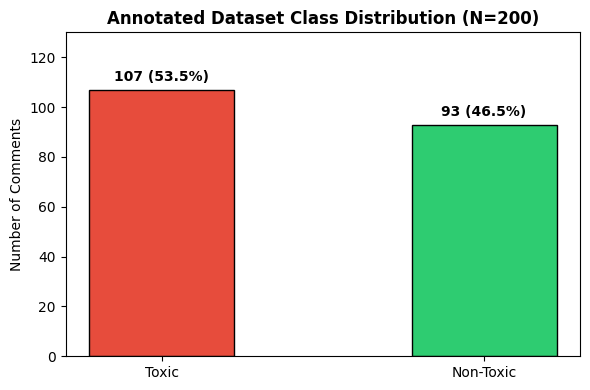

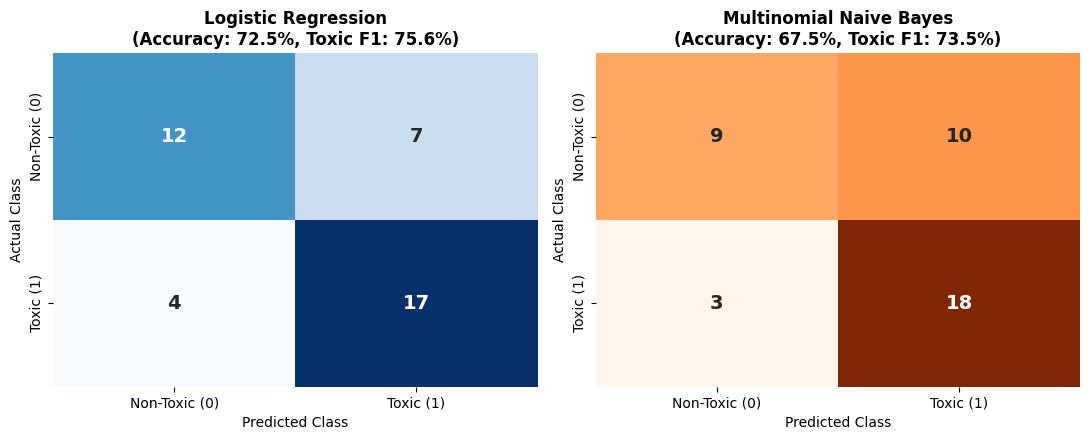

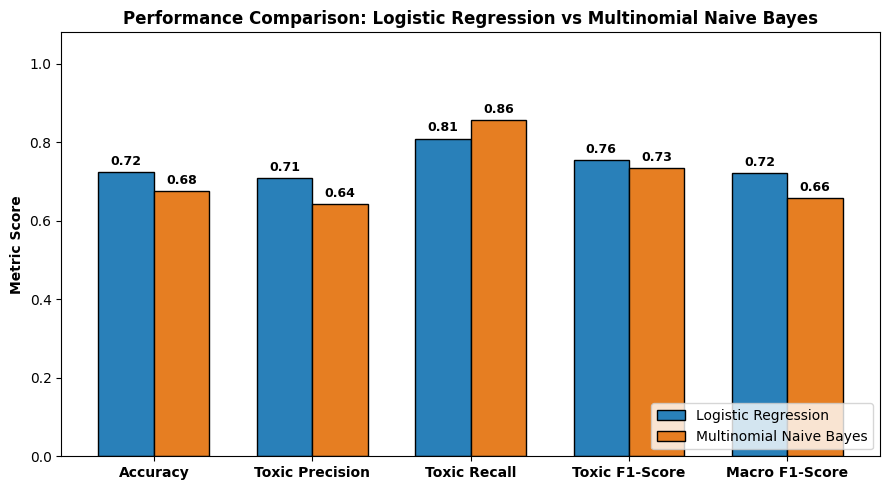

In [12]:
# 1. Class Distribution
fig, ax = plt.subplots(figsize=(6, 4))
counts = df["manual_label"].value_counts()
bars = ax.bar(counts.index, counts.values, color=["#e74c3c", "#2ecc71"], edgecolor="black", width=0.45)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h} ({h/len(df)*100:.1f}%)", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
ax.set_title("Annotated Dataset Class Distribution (N=200)", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of Comments")
ax.set_ylim(0, 130)
plt.tight_layout()
plt.show()

# 2. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(m_lr["Confusion Matrix"], annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=["Non-Toxic (0)", "Toxic (1)"], yticklabels=["Non-Toxic (0)", "Toxic (1)"],
            annot_kws={"size": 14, "weight": "bold"})
axes[0].set_title(f"Logistic Regression\n(Accuracy: {m_lr['Accuracy']*100:.1f}%, Toxic F1: {m_lr['Toxic F1-Score']*100:.1f}%)", fontweight="bold")
axes[0].set_ylabel("Actual Class")
axes[0].set_xlabel("Predicted Class")

sns.heatmap(m_nb["Confusion Matrix"], annot=True, fmt="d", cmap="Oranges", ax=axes[1], cbar=False,
            xticklabels=["Non-Toxic (0)", "Toxic (1)"], yticklabels=["Non-Toxic (0)", "Toxic (1)"],
            annot_kws={"size": 14, "weight": "bold"})
axes[1].set_title(f"Multinomial Naive Bayes\n(Accuracy: {m_nb['Accuracy']*100:.1f}%, Toxic F1: {m_nb['Toxic F1-Score']*100:.1f}%)", fontweight="bold")
axes[1].set_ylabel("Actual Class")
axes[1].set_xlabel("Predicted Class")

plt.tight_layout()
plt.show()

# 3. Bar Chart Comparison
metric_names = ["Accuracy", "Toxic Precision", "Toxic Recall", "Toxic F1-Score", "Macro F1-Score"]
lr_vals = [m_lr["Accuracy"], m_lr["Toxic Precision"], m_lr["Toxic Recall"], m_lr["Toxic F1-Score"], m_lr["Macro F1-Score"]]
nb_vals = [m_nb["Accuracy"], m_nb["Toxic Precision"], m_nb["Toxic Recall"], m_nb["Toxic F1-Score"], m_nb["Macro F1-Score"]]

x = np.arange(len(metric_names))
w = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
r1 = ax.bar(x - w/2, lr_vals, w, label="Logistic Regression", color="#2980b9", edgecolor="black")
r2 = ax.bar(x + w/2, nb_vals, w, label="Multinomial Naive Bayes", color="#e67e22", edgecolor="black")

ax.set_ylabel("Metric Score", fontweight="bold")
ax.set_title("Performance Comparison: Logistic Regression vs Multinomial Naive Bayes", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontweight="bold")
ax.set_ylim(0, 1.08)
ax.legend(loc="lower right")

for rect in list(r1) + list(r2):
    h = rect.get_height()
    ax.annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


### 13. Prediction on New Comments (Inference)
We evaluate the 4 required test sentences:
1. `"Thank you for helping me."`
2. `"You are an idiot."`
3. `"I appreciate your hard work."`
4. `"You are useless."`

**Academic Observations:**
- **Out-of-Vocabulary (OOV) Terms:** Words not observed in training (e.g., *'useless'*) receive 0 TF-IDF weight. The model defaults to its baseline intercept probability.
- **Probability vs Certainty:** Confidence probability reflects learned feature weights, not ground-truth certainty. Subtle nuances and context require large-scale contextual language models.


In [13]:
def predict_comment_toxicity(comment, model, vectorizer):
    """Preprocess text, transform to TF-IDF, and output predicted label & confidence."""
    processed = preprocess_pipeline(comment)
    vec = vectorizer.transform([processed])
    pred_idx = model.predict(vec)[0]
    probs = model.predict_proba(vec)[0]
    
    label_str = "Toxic" if pred_idx == 1 else "Non-Toxic"
    confidence = probs[pred_idx]
    
    vocab = vectorizer.get_feature_names_out()
    in_vocab = [w for w in processed.split() if w in vocab]
    
    return {
        "comment": comment,
        "processed": processed,
        "in_vocab": in_vocab,
        "prediction": label_str,
        "confidence": confidence,
        "prob_toxic": probs[1],
        "prob_non_toxic": probs[0]
    }

test_comments = [
    "Thank you for helping me.",
    "You are an idiot.",
    "I appreciate your hard work.",
    "You are useless."
]

print("=== INFERENCE USING SELECTED MODEL (Logistic Regression) ===")
for c in test_comments:
    res = predict_comment_toxicity(c, lr_model, tfidf)
    print(f"\nInput Comment:     '{res['comment']}'")
    print(f"Preprocessed:      {res['processed']}")
    print(f"Tokens in Vocab:   {res['in_vocab']}")
    print(f"Predicted Class:   {res['prediction']}")
    print(f"Confidence:        {res['confidence']*100:.2f}% (P(Toxic)={res['prob_toxic']:.4f})")


=== INFERENCE USING SELECTED MODEL (Logistic Regression) ===

Input Comment:     'Thank you for helping me.'
Preprocessed:      thank helping
Tokens in Vocab:   ['thank']
Predicted Class:   Toxic
Confidence:        50.48% (P(Toxic)=0.5048)

Input Comment:     'You are an idiot.'
Preprocessed:      idiot
Tokens in Vocab:   ['idiot']
Predicted Class:   Toxic
Confidence:        64.38% (P(Toxic)=0.6438)

Input Comment:     'I appreciate your hard work.'
Preprocessed:      appreciate hard work
Tokens in Vocab:   ['appreciate', 'work']
Predicted Class:   Toxic
Confidence:        52.78% (P(Toxic)=0.5278)

Input Comment:     'You are useless.'
Preprocessed:      useless
Tokens in Vocab:   ['useless']
Predicted Class:   Toxic
Confidence:        53.84% (P(Toxic)=0.5384)


### 14. Saving the Selected Model & Vectorizer
We serialize the trained **Logistic Regression** model and the fitted **TF-IDF vectorizer** using `joblib`.
We then demonstrate reloading both artifacts into memory and testing an inference sample.


In [14]:
models_dir = "../models" if os.path.exists("../models") else "models"
os.makedirs(models_dir, exist_ok=True)

model_path = os.path.join(models_dir, "toxic_comment_model.pkl")
vectorizer_path = os.path.join(models_dir, "tfidf_vectorizer.pkl")

# Save artifacts
joblib.dump(lr_model, model_path)
joblib.dump(tfidf, vectorizer_path)
print(f"Saved Model to:      {model_path}")
print(f"Saved Vectorizer to: {vectorizer_path}")

# Load back and verify
loaded_model = joblib.load(model_path)
loaded_vec = joblib.load(vectorizer_path)

test_sample = "You are an idiot."
verification = predict_comment_toxicity(test_sample, loaded_model, loaded_vec)
print(f"\nVerification Test:")
print(f"Comment: '{test_sample}' -> Prediction: {verification['prediction']} (Confidence: {verification['confidence']*100:.2f}%)")


Saved Model to:      ../models\toxic_comment_model.pkl
Saved Vectorizer to: ../models\tfidf_vectorizer.pkl

Verification Test:
Comment: 'You are an idiot.' -> Prediction: Toxic (Confidence: 64.38%)


### 15. Final Observations and Conclusion

#### Key Findings
- **Logistic Regression** achieved **72.50% Accuracy**, **70.83% Toxic Precision**, **80.95% Toxic Recall**, and **75.56% Toxic F1-Score**.
- **Multinomial Naive Bayes** achieved **67.50% Accuracy**, **64.29% Toxic Precision**, **85.71% Toxic Recall**, and **73.47% Toxic F1-Score**.
- **Model Selection:** Logistic Regression is chosen as the primary model due to superior toxic precision (70.83% vs 64.29%), higher accuracy (72.5% vs 67.5%), and fewer false positives (7 vs 10).

#### Limitations & Future Work
1. **Sample Size:** 200 comments (160 train / 40 test) produces high metric variance. Each misclassified test instance alters accuracy by 2.5%.
2. **Out-of-Vocabulary Vulnerability:** Linear TF-IDF models cannot infer semantic similarity for unseen words.
3. **Future Work:** Scaled training on the full 159k Wikipedia dataset (`train.csv`) and fine-tuning Transformer architectures (BERT / RoBERTa) to capture deep context and sarcasm.
